# 03 · Análisis del consumo

**Entrada:** `data/processed/consumo_horario.parquet` (datos limpios, en MW reales).
**Funciones:** `src/features.py` (`agregar_variables_temporales`, `normalizar_por_region`).

| Sección | Qué responde | Historia de usuario |
|---|---|---|
| 1 | Patrones por hora, día de la semana y estación | HU-01 |
| 2 | Estacionalidad y tendencia de largo plazo | HU-02 |
| 3 | Comparación entre regiones | HU-03 |
| 4 | Periodos de máxima demanda | HU-04 |
| 5 | Efecto de los festivos | Variable `es_festivo` |
| 6 | Pendientes de la exploración (desfase de `COMED`, empalmes entre regiones) | Calidad y comparabilidad |
| 7 | Conclusiones | Resultados esperados |

**Qué datos usa cada sección:** las comparaciones entre regiones usan las regiones vigentes en su periodo común, la estacionalidad, la tendencia y los picos usan todo el historial de cada región.

## 0. Configuración y carga

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL

from src.config import PROCESSED_DIR
from src.features import agregar_variables_temporales, normalizar_por_region

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
ESTACIONES = ['Invierno', 'Primavera', 'Verano', 'Otoño']

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")
df = normalizar_por_region(agregar_variables_temporales(df))

print(f"{len(df):,} filas · {df['region'].nunique()} regiones")
df.head()

1,090,343 filas · 12 regiones


,Datetime,MW,region,anio,mes,hora,dia_semana,es_fin_de_semana,estacion,es_festivo,MW_rel
0,2004-10-01 01:00:00,12379.0,AEP,2004,10,1,4,False,Otoño,False,0.798689
1,2004-10-01 02:00:00,11935.0,AEP,2004,10,2,4,False,Otoño,False,0.770042
2,2004-10-01 03:00:00,11692.0,AEP,2004,10,3,4,False,Otoño,False,0.754364
3,2004-10-01 04:00:00,11597.0,AEP,2004,10,4,4,False,Otoño,False,0.748235
4,2004-10-01 05:00:00,11681.0,AEP,2004,10,5,4,False,Otoño,False,0.753654


### Regiones vigentes y periodo común

Las regiones vigentes son las que llegan hasta el final del dataset. Sus datos dentro del periodo común (`df_comun`) son los que se comparan entre sí.

In [3]:
cobertura = df.groupby('region')['Datetime'].agg(inicio='min', fin='max')

corte = cobertura['fin'].max() - pd.Timedelta(days=7)
vigentes = cobertura[cobertura['fin'] >= corte]
inicio_comun, fin_comun = vigentes['inicio'].max(), vigentes['fin'].min()

df_comun = df[df['region'].isin(vigentes.index) & df['Datetime'].between(inicio_comun, fin_comun)]

print(f"Regiones vigentes ({len(vigentes)}): {list(vigentes.index)}")
print(f"Periodo común: {inicio_comun:%Y-%m-%d} → {fin_comun:%Y-%m-%d}")
print("Fuera de la comparación:", [r for r in cobertura.index if r not in vigentes.index])

Regiones vigentes (10): ['AEP', 'COMED', 'DAYTON', 'DEOK', 'DOM', 'DUQ', 'EKPC', 'FE', 'PJME', 'PJMW']
Periodo común: 2013-06-01 → 2018-08-03
Fuera de la comparación: ['NI', 'PJM_Load']


### Años completos

Para tendencia y picos anuales solo se usan los años con (casi) todas sus horas. Si no, un año parcial (como 2018, que llega hasta agosto) parecería una caída.

In [4]:
por_anio = df.groupby(['region', 'anio'])['MW'].agg(media='mean', maximo='max', horas='count')
por_anio['completo'] = por_anio['horas'] >= 8700

print(f"{int(por_anio['completo'].sum())} de {len(por_anio)} combinaciones región-año son completas")
completos = por_anio[por_anio['completo']].reset_index()[['region', 'anio']]

114 de 134 combinaciones región-año son completas


### Promedio diario (solo días completos)

El primer y el último día de cada serie pueden tener pocas horas (por ejemplo, el último día termina a las 00:00 con una sola hora). Su promedio no es comparable, así que los promedios diarios se calculan solo con días de 24 horas.

In [5]:
def promedio_diario(d):
    r = d.set_index('Datetime').groupby('region')['MW'].resample('D')
    return r.mean()[r.count() == 24]

## 1. Patrones temporales

### 1.1 Hora del día por día de la semana

Consumo relativo al promedio de cada región (regiones vigentes, periodo común). Muestra cómo interactúan las dos variables, algo que los perfiles por separado no capturan.

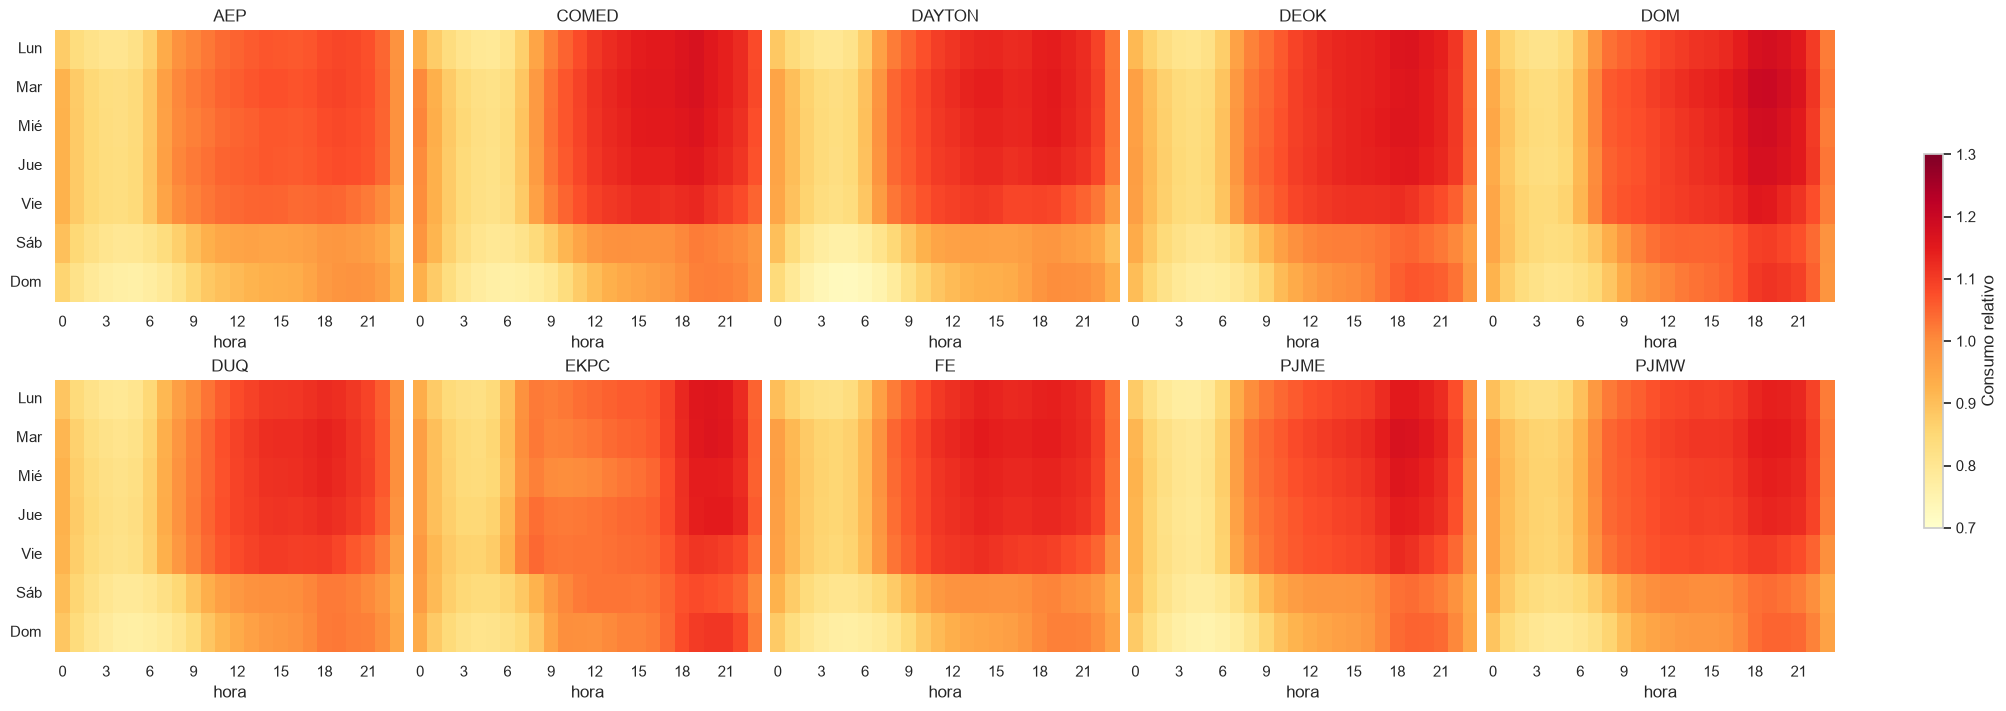

In [6]:
regs = list(vigentes.index)
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True, layout='constrained')

for ax, nombre in zip(axes.flat, regs):
    p = (df_comun[df_comun['region'] == nombre]
         .groupby(['dia_semana', 'hora'])['MW_rel'].mean().unstack())
    sns.heatmap(p, ax=ax, cmap='YlOrRd', vmin=0.7, vmax=1.3, cbar=False,
                yticklabels=DIAS, xticklabels=3)
    ax.set_title(nombre)
    ax.set_xlabel('hora')
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0)

fig.colorbar(axes.flat[0].collections[0], ax=axes, shrink=0.6, label='Consumo relativo')
plt.show()

### 1.2 Perfil horario por estación

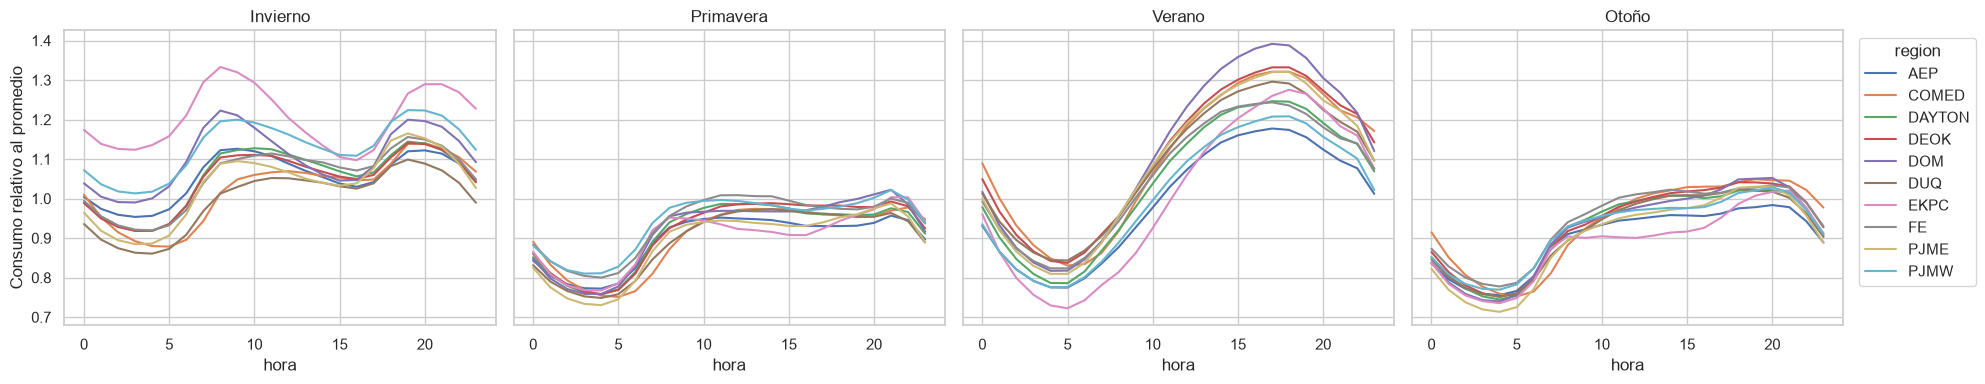

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)

for ax, est in zip(axes, ESTACIONES):
    p = (df_comun[df_comun['estacion'] == est]
         .groupby(['region', 'hora'])['MW_rel'].mean().unstack(0))
    p.plot(ax=ax, legend=False)
    ax.set_title(est)

axes[-1].legend(title='region', bbox_to_anchor=(1.02, 1), loc='upper left')
axes[0].set_ylabel('Consumo relativo al promedio')
plt.tight_layout()
plt.show()

## 2. Estacionalidad y tendencia

### 2.1 Tendencia por región

Promedio diario (línea tenue) y media móvil de 365 días (línea gruesa), que cancela la estacionalidad anual. Usa todo el historial de cada región y solo días completos.

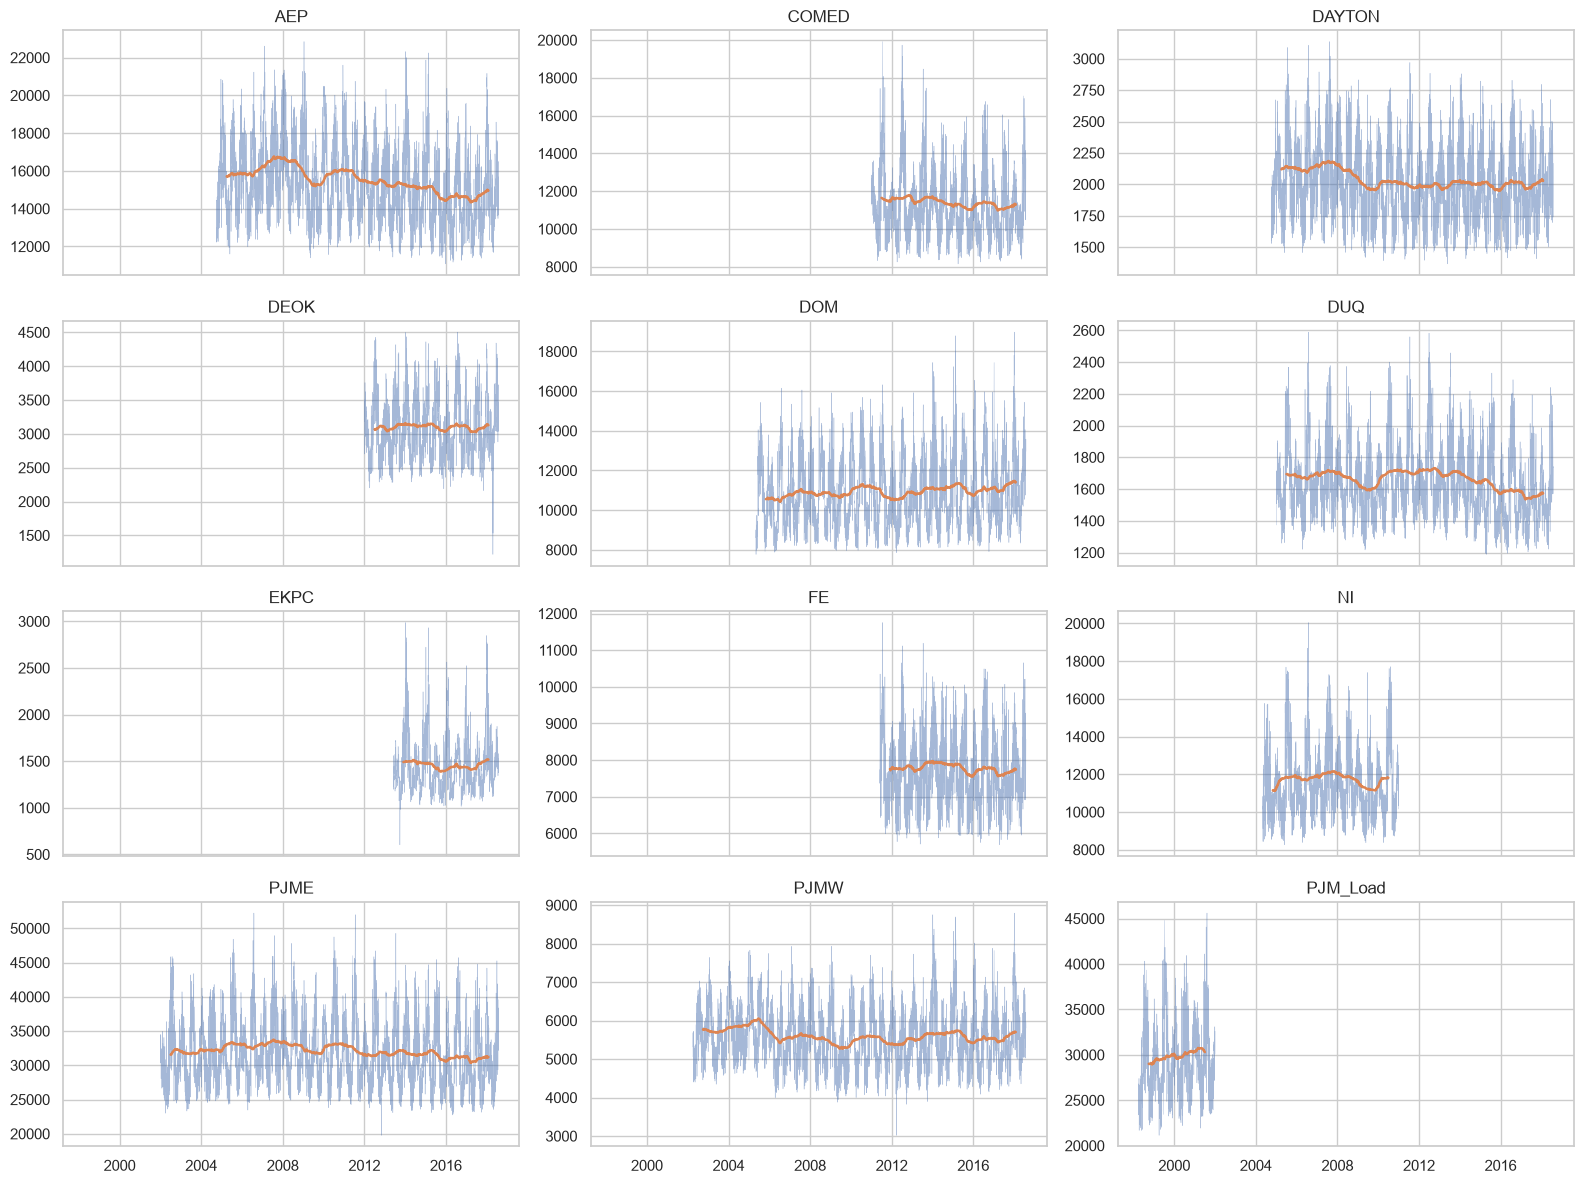

In [8]:
diario = promedio_diario(df)
nombres = list(cobertura.index)

fig, axes = plt.subplots(4, 3, figsize=(16, 12), sharex=True)
for ax, nombre in zip(axes.flat, nombres):
    s = diario[nombre]
    ax.plot(s.index, s.values, linewidth=0.3, alpha=0.5)
    ax.plot(s.index, s.rolling(365, center=True).mean(), linewidth=1.8)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

### 2.2 Consumo medio por año completo

In [9]:
anual = (por_anio[por_anio['completo']]['media'].unstack(0))
anual.round(0)

region,AEP,COMED,DAYTON,DEOK,DOM,DUQ,EKPC,FE,NI,PJME,PJMW,PJM_Load
anio,,,,,,,,,,,,
2005,15842.0,NaN,2142.0,NaN,NaN,1693.0,NaN,NaN,11851.0,33308.0,6038.0,NaN
2006,15736.0,NaN,2096.0,NaN,10456.0,1663.0,NaN,NaN,11687.0,32407.0,5425.0,NaN
2007,16645.0,NaN,2178.0,NaN,10990.0,1713.0,NaN,NaN,12085.0,33611.0,5635.0,NaN
2008,16536.0,NaN,2114.0,NaN,10786.0,1674.0,NaN,NaN,11874.0,32928.0,5530.0,NaN
2009,15253.0,NaN,1965.0,NaN,10696.0,1594.0,NaN,NaN,11213.0,31849.0,5290.0,NaN
2010,16008.0,NaN,2027.0,NaN,11280.0,1708.0,NaN,NaN,11816.0,33099.0,5573.0,NaN
2011,15815.0,11648.0,1989.0,NaN,10865.0,1704.0,NaN,NaN,NaN,32366.0,5509.0,NaN
2012,15352.0,11612.0,1982.0,3065.0,10614.0,1719.0,NaN,7754.0,NaN,31439.0,5395.0,NaN
2013,15198.0,11549.0,1989.0,3091.0,10904.0,1692.0,NaN,7806.0,NaN,31705.0,5557.0,NaN


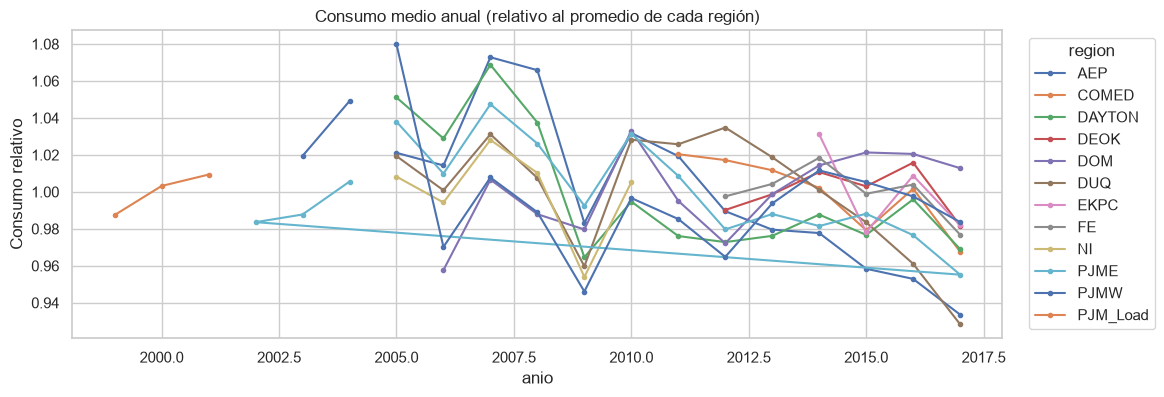

In [10]:
(anual / anual.mean()).plot(figsize=(12, 4), marker='o', markersize=3)
plt.title('Consumo medio anual (relativo al promedio de cada región)')
plt.ylabel('Consumo relativo')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='region')
plt.show()

### 2.3 Descomposición STL

Separa la serie diaria en tendencia, estacionalidad anual y residuo.

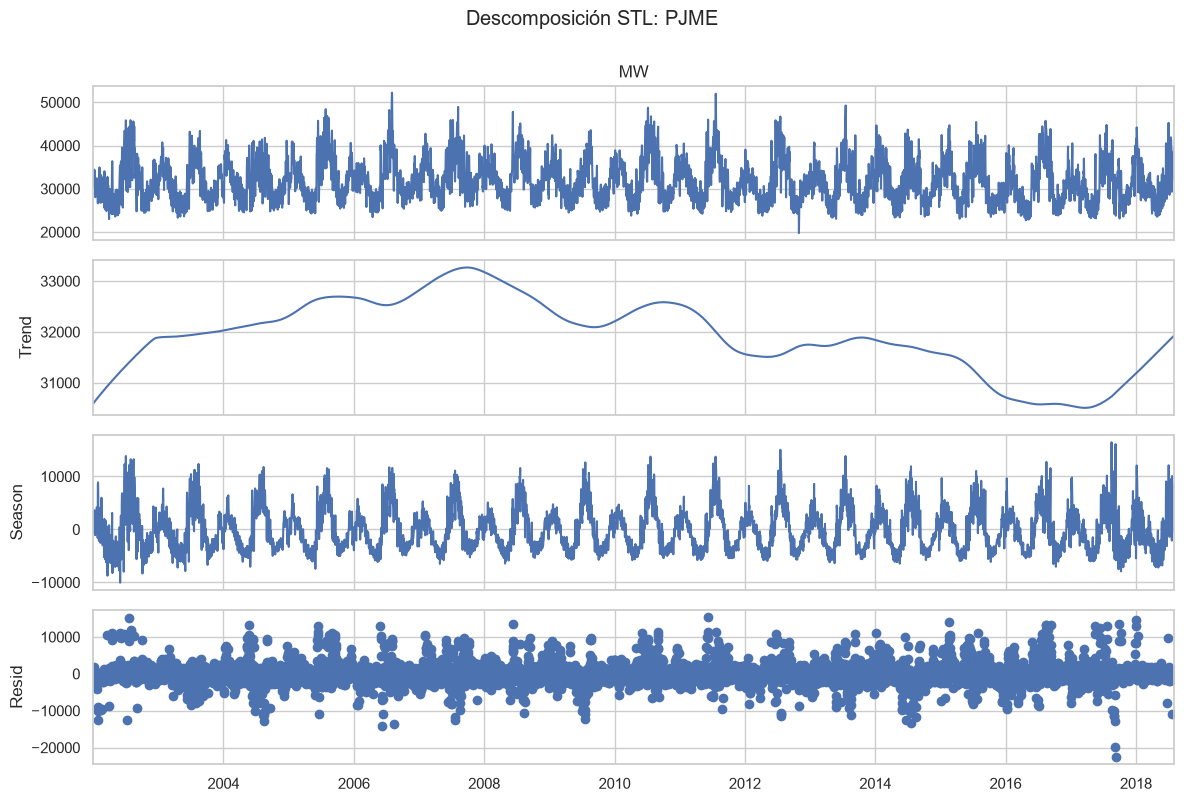

In [11]:
region_stl = 'PJME'    # cambiar por la región que se quiera descomponer

serie = diario[region_stl].asfreq('D').interpolate()
resultado = STL(serie, period=365, robust=True).fit()

fig = resultado.plot()
fig.set_size_inches(12, 8)
fig.suptitle(f'Descomposición STL: {region_stl}', y=1.0)
plt.tight_layout()
plt.show()

## 3. Comparación entre regiones

Regiones vigentes en su periodo común. Cada columna resume una característica del consumo:

- `CV_%`: variabilidad relativa (desviación estándar entre la media).
- `pico/media`: cuánto se dispara el máximo respecto al promedio.
- `invierno/verano`: consumo medio de invierno entre el de verano (mayor que 1: región invernal).
- `fin_de_semana_%`: diferencia del consumo de fin de semana frente a días laborables.
- `hora_pico`: hora del día con mayor consumo promedio.

In [12]:
g = df_comun.groupby('region')['MW']
perfil_horario = df_comun.groupby(['region', 'hora'])['MW'].mean().unstack(0)

media_estacion = df_comun.groupby(['region', 'estacion'])['MW'].mean().unstack()
media_finde = df_comun.groupby(['region', 'es_fin_de_semana'])['MW'].mean().unstack()

resumen = pd.DataFrame({
    'media_MW': g.mean(),
    'CV_%': g.std() / g.mean() * 100,
    'pico/media': g.max() / g.mean(),
    'invierno/verano': media_estacion['Invierno'] / media_estacion['Verano'],
    'fin_de_semana_%': (media_finde[True] / media_finde[False] - 1) * 100,
    'hora_pico': perfil_horario.idxmax(),
})
resumen.round(2)

,media_MW,CV_%,pico/media,invierno/verano,fin_de_semana_%,hora_pico
region,,,,,,
AEP,14900.18,16.94,1.66,1.06,-9.45,19
COMED,11361.78,19.73,1.96,0.93,-11.04,19
DAYTON,2008.91,18.95,1.69,1.01,-13.85,19
DEOK,3119.96,19.36,1.70,0.95,-9.16,19
DOM,11169.09,22.20,1.94,0.98,-5.98,19
DUQ,1621.70,18.69,1.82,0.92,-8.75,18
EKPC,1464.23,25.87,2.38,1.20,-3.83,20
FE,7791.76,16.93,1.69,1.00,-11.56,19
PJME,31477.51,20.48,1.88,0.95,-9.12,18


### 3.1 Correlación entre regiones

Se calcula sobre el promedio diario. Valores altos indican que las regiones suben y bajan juntas, en buena parte por compartir la estacionalidad.

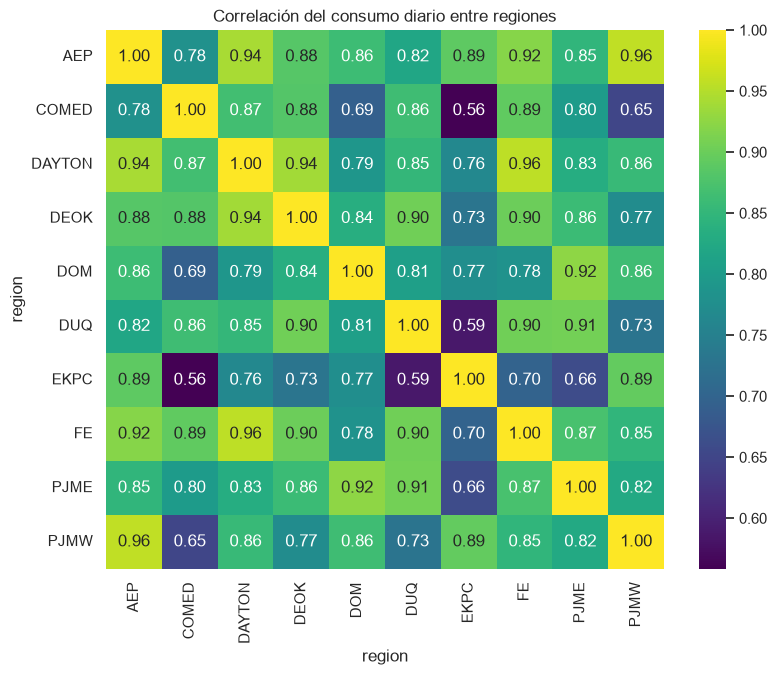

In [13]:
diario_comun = promedio_diario(df_comun).unstack(0)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(diario_comun.corr(), annot=True, fmt='.2f', cmap='viridis', ax=ax)
ax.set_title('Correlación del consumo diario entre regiones')
plt.show()

## 4. Periodos de máxima demanda

Usa todo el historial de cada región.

### 4.1 Máximo de cada región

In [14]:
idx = df.groupby('region')['MW'].idxmax()
maximos = df.loc[idx, ['region', 'Datetime', 'MW', 'estacion']].set_index('region')
maximos['pico/media'] = maximos['MW'] / df.groupby('region')['MW'].mean()
maximos.round({'MW': 1, 'pico/media': 2})

,Datetime,MW,estacion,pico/media
region,,,,
AEP,2008-10-20 14:00:00,25695.0,Otoño,1.66
COMED,2011-07-20 18:00:00,23753.0,Verano,2.08
DAYTON,2007-08-08 15:00:00,3746.0,Verano,1.84
DEOK,2012-06-29 16:00:00,5445.0,Verano,1.75
DOM,2015-02-20 08:00:00,21651.0,Invierno,1.98
DUQ,2012-06-29 14:00:00,3054.0,Verano,1.84
EKPC,2015-02-20 08:00:00,3490.0,Invierno,2.38
FE,2011-07-21 16:00:00,14032.0,Verano,1.80
NI,2006-08-01 17:00:00,23631.0,Verano,2.02


### 4.2 Los 5 días de mayor pico por región

In [15]:
max_diario = df.set_index('Datetime').groupby('region')['MW'].resample('D').max()

top_dias = (max_diario.groupby(level='region', group_keys=False).nlargest(5)
            .rename('MW_pico').reset_index())
top_dias['dia'] = top_dias['Datetime'].dt.strftime('%Y-%m-%d')
top_dias.pivot_table(index=top_dias.groupby('region').cumcount() + 1,
                     columns='region', values='dia', aggfunc='first')

region,AEP,COMED,DAYTON,DEOK,DOM,DUQ,EKPC,FE,NI,PJME,PJMW,PJM_Load
1,2008-10-20,2011-07-20,2007-08-08,2012-06-29,2015-02-20,2012-06-29,2015-02-20,2011-07-21,2006-08-01,2006-08-02,2015-02-20,2001-08-09
2,2007-08-08,2011-07-21,2007-08-09,2012-07-17,2018-01-07,2006-08-03,2018-01-02,2011-07-22,2006-07-31,2006-08-03,2015-02-19,2001-08-08
3,2007-08-09,2012-07-06,2005-07-25,2012-07-25,2018-01-03,2006-08-02,2014-01-29,2012-07-17,2006-08-02,2011-07-22,2015-02-24,2001-08-07
4,2007-08-23,2012-07-17,2006-08-01,2012-07-06,2018-01-02,2012-07-17,2014-01-06,2011-07-20,2006-07-17,2006-08-01,2014-01-07,2001-07-25
5,2006-08-02,2012-07-05,2007-08-07,2016-07-25,2012-07-07,2011-07-21,2014-01-24,2013-07-18,2007-08-07,2011-07-21,2018-01-05,2001-08-10


### 4.3 ¿A qué hora ocurre el pico de cada día?

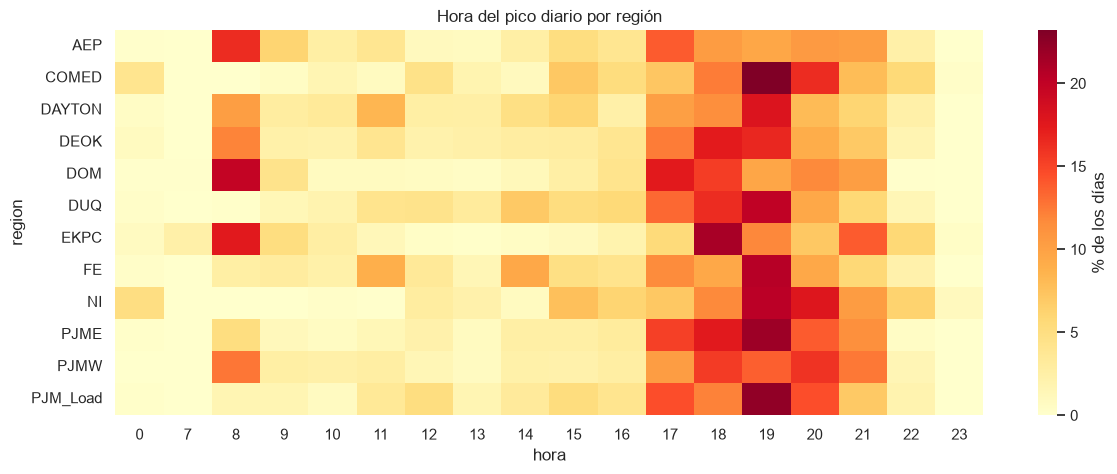

In [16]:
df['fecha'] = df['Datetime'].dt.normalize()
pico_dia = df.loc[df.groupby(['region', 'fecha'])['MW'].idxmax()]

horas_pico = pd.crosstab(pico_dia['region'], pico_dia['hora'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(horas_pico, cmap='YlOrRd', ax=ax, cbar_kws={'label': '% de los días'})
ax.set_title('Hora del pico diario por región')
plt.show()

### 4.4 Pico anual: en qué mes ocurre y cuánto vale (años completos)

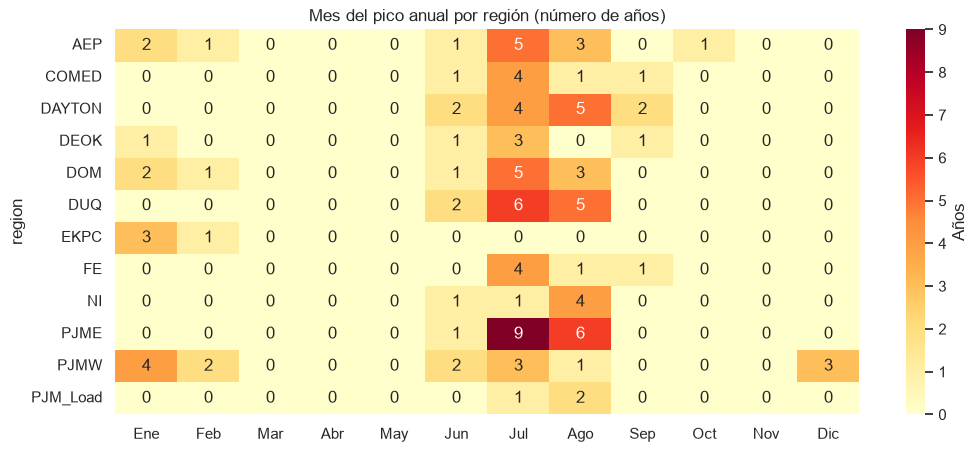

In [17]:
pico_anual = df.loc[df.groupby(['region', 'anio'])['MW'].idxmax()]
pico_anual = pico_anual.merge(completos, on=['region', 'anio'])

meses_pico = pd.crosstab(pico_anual['region'], pico_anual['mes']).reindex(columns=range(1, 13), fill_value=0)
meses_pico.columns = MESES

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(meses_pico, annot=True, fmt='d', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Años'})
ax.set_title('Mes del pico anual por región (número de años)')
plt.show()

In [18]:
pico_anual.pivot(index='anio', columns='region', values='MW').round(0)

region,AEP,COMED,DAYTON,DEOK,DOM,DUQ,EKPC,FE,NI,PJME,PJMW,PJM_Load
anio,,,,,,,,,,,,
1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51714.0
2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49462.0
2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,54030.0
2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55934.0,NaN,NaN
2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53737.0,8437.0,NaN
2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51962.0,8598.0,NaN
2005,24015.0,NaN,3722.0,NaN,NaN,2885.0,NaN,NaN,21635.0,59031.0,8823.0,NaN
2006,24842.0,NaN,3693.0,NaN,19395.0,3053.0,NaN,NaN,23631.0,62009.0,8734.0,NaN
2007,25164.0,NaN,3746.0,NaN,19709.0,2890.0,NaN,NaN,21972.0,59437.0,8664.0,NaN


## 5. Efecto de los festivos

Los festivos son los federales de EE. UU. (aproximación: PJM abarca varios estados con calendarios propios). Se compara el perfil horario de días laborables, fines de semana y festivos.

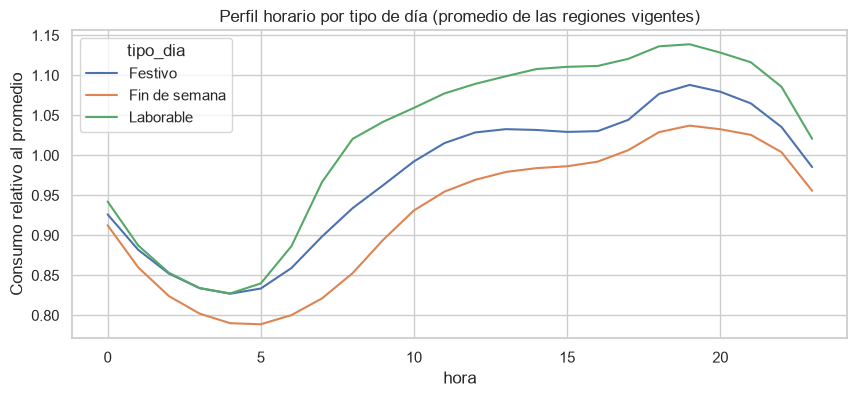

In [19]:
df_comun = df_comun.assign(
    tipo_dia=np.select(
        [df_comun['es_festivo'], df_comun['es_fin_de_semana']],
        ['Festivo', 'Fin de semana'],
        default='Laborable',
    )
)

perfil_tipo = df_comun.groupby(['tipo_dia', 'hora'])['MW_rel'].mean().unstack(0)
perfil_tipo.plot(figsize=(10, 4), title='Perfil horario por tipo de día (promedio de las regiones vigentes)')
plt.ylabel('Consumo relativo al promedio')
plt.show()

In [20]:
medias_tipo = df_comun.groupby(['region', 'tipo_dia'])['MW'].mean().unstack()
dif_festivo = pd.DataFrame({
    'festivo_vs_laborable_%': (medias_tipo['Festivo'] / medias_tipo['Laborable'] - 1) * 100,
    'finde_vs_laborable_%': (medias_tipo['Fin de semana'] / medias_tipo['Laborable'] - 1) * 100,
})
dif_festivo.round(1)

,festivo_vs_laborable_%,finde_vs_laborable_%
region,,
AEP,-5.2,-9.6
COMED,-7.8,-11.3
DAYTON,-8.9,-14.1
DEOK,-5.8,-9.3
DOM,-0.7,-6.0
DUQ,-4.7,-8.9
EKPC,2.0,-3.7
FE,-8.4,-11.8
PJME,-4.8,-9.2


## 6. Pendientes de la exploración

### 6.1 ¿`COMED` está desfasada respecto a las demás regiones?

Se compara su perfil horario con el promedio del resto, desplazado entre -3 y +3 horas. Un desplazamiento positivo con el menor error indica que `COMED` va retrasada esas horas (por ejemplo, por la zona horaria).

In [21]:
perfiles = df_comun.groupby(['region', 'hora'])['MW_rel'].mean().unstack(0)
referencia = perfiles.drop(columns='COMED').mean(axis=1)

errores = {
    k: float(np.abs(perfiles['COMED'].values - np.roll(referencia.values, k)).mean())
    for k in range(-3, 4)
}
desfase = pd.Series(errores, name='error_medio').rename_axis('desplazamiento_h').to_frame()
desfase.round(4)

,error_medio
desplazamiento_h,
-3,0.0856
-2,0.0653
-1,0.0443
0,0.0242
1,0.0142
2,0.0355
3,0.0593


In [22]:
print("Desplazamiento con menor error:", desfase['error_medio'].idxmin(), "h")

Desplazamiento con menor error: 1 h


### 6.2 Empalmes entre regiones

Si una región termina cuando empieza otra y representan la misma zona, sus niveles deberían ser parecidos en el empalme. Se comparan las medias de los últimos 30 días de la primera y los primeros 30 de la segunda. Es solo una pista: los dos tramos son de épocas distintas del año y las regiones pueden diferir en tamaño.

In [23]:
empalmes = [('NI', 'COMED'), ('PJM_Load', 'PJME'), ('PJM_Load', 'PJMW')]
filas = []

for a, b in empalmes:
    da = df[df['region'] == a]
    db = df[df['region'] == b]
    fin_a, inicio_b = da['Datetime'].max(), db['Datetime'].min()
    ultimos = da[da['Datetime'] > fin_a - pd.Timedelta(days=30)]['MW'].mean()
    primeros = db[db['Datetime'] < inicio_b + pd.Timedelta(days=30)]['MW'].mean()
    filas.append({
        'termina': a, 'fin': fin_a,
        'empieza': b, 'inicio': inicio_b,
        'media_ultimos_30d': ultimos,
        'media_primeros_30d': primeros,
        'cociente': primeros / ultimos,
    })

pd.DataFrame(filas).round({'media_ultimos_30d': 0, 'media_primeros_30d': 0, 'cociente': 2})

,termina,fin,empieza,inicio,media_ultimos_30d,media_primeros_30d,cociente
0,NI,2011-01-01,COMED,2011-01-01 01:00:00,12230.0,12242.0,1.00
1,PJM_Load,2002-01-01,PJME,2002-01-01 01:00:00,29679.0,31091.0,1.05
2,PJM_Load,2002-01-01,PJMW,2002-04-01 01:00:00,29679.0,5170.0,0.17


## 7. Conclusiones

| Objetivo | Hallazgo |
|---|---|
| Patrones por hora, día de la semana y mes (HU-01) | El consumo toca fondo hacia las 4–5 h (≈0.83 del promedio), sube desde las 6 h y alcanza su máximo diario entre las 18 y las 20 h (19 h en 7 de 10 regiones, DUQ y PJME a las 18 h, EKPC a las 20 h). Los fines de semana consumen entre 4 % (EKPC) y 14 % (DAYTON) menos que los laborables (≈ −9 % en promedio), y el domingo de madrugada es el momento más bajo. La forma del día cambia con la estación: en verano hay una sola curva con máximo por la tarde y la noche (hasta 1.2–1.4 del promedio), en invierno hay dos picos, uno hacia las 8 h y otro hacia las 19–20 h, primavera y otoño son los meses más planos y suaves. |
| Estacionalidad y tendencia de largo plazo (HU-02) | La estacionalidad anual es fuerte (en PJME el componente estacional oscila unos ±10 000 MW), con un máximo en verano y un repunte secundario en invierno. No hay crecimiento de largo plazo, sino estabilidad o ligera baja: PJME pasó de 33 611 MW (2007) a 30 652 MW (2017), −9 %, AEP de 16 645 a 14 484 (−13 %), DUQ −10 %. DOM sube ≈6 % desde 2006, DAYTON y PJMW se mantienen planas. Hay un máximo común en 2007 y una caída en 2009. La tendencia STL de PJME toca fondo en 2016–2017 y luego sube, pero el final de la serie es poco fiable (efecto de borde). |
| Comparación entre regiones (HU-03) | Los tamaños son muy distintos (PJME 31 478 MW de media frente a EKPC 1 464 MW), por lo que conviene comparar con `MW_rel`. La variabilidad (CV) va de 17 % (AEP, FE) a 26 % (EKPC) y el pico/media de 1.66 a 2.38. COMED (0.93), DUQ (0.92), DEOK y PJME (0.95) son regiones de verano, EKPC (1.20) y PJMW (1.12) tienen sesgo invernal. Las correlaciones diarias son altas (0.56–0.96) porque comparten estacionalidad, los pares más parecidos son AEP–PJMW y DAYTON–FE (0.96). La región más distinta es EKPC (0.56 con COMED, 0.59 con DUQ), seguida de COMED (0.65–0.69 con PJMW y DOM). |
| Periodos de máxima demanda (HU-04) | Los máximos históricos son casi siempre olas de calor de verano: PJME 62 009 MW (2-ago-2006), COMED, DAYTON, DUQ, DEOK, FE y NI también en julio o agosto. Las excepciones son invernales: DOM, EKPC y PJMW tienen su récord el mismo día, el 20-feb-2015 a las 8 h. Los 5 días más altos se agrupan en episodios concretos (ago-2006, jul-2011, jun/jul-2012, ene-2014, feb-2015, ene-2018). El pico anual de PJME cae en julio (9 años) o agosto (6) en 15 de 16 años, EKPC es 100 % invernal (ene/feb), PJMW, AEP y DOM son mixtas. El pico diario ocurre sobre todo a las 19 h, y en las regiones de sesgo invernal (DOM, EKPC, AEP, PJMW) hay un segundo grupo de picos a las 8 h. El máximo de AEP (20-oct-2008) es atípico y conviene verificarlo. |
| Efecto de los festivos | Un festivo consume en promedio ≈5 % menos que un laborable (de −0.7 % en DOM a −8.9 % en DAYTON, EKPC es la excepción con +2 %), aproximadamente la mitad del efecto de un fin de semana (≈ −9 %). El perfil conserva la forma del día laborable pero desplazado hacia abajo, con la mayor diferencia entre las 7 y las 20 h, de madrugada (0–5 h) los tres tipos de día casi coinciden. Al ser festivos federales aproximados, el efecto real de los festivos más marcados es mayor que este promedio. |
| Desfase de `COMED` y empalmes entre regiones | `COMED` encaja mejor con el resto con un desplazamiento de +1 h (error 0.014 frente a 0.024 sin desplazar), compatible con que esté en hora local central, hay que confirmarlo con la documentación de la fuente antes de corregirlo. Empalmes: NI → COMED tiene cociente 1.00 (12 230 vs 12 242 MW) y se tocan el 1-ene-2011, así que son la misma zona y pueden unirse en una serie más larga. PJM_Load → PJME da 1.05, compatible con una continuación. PJM_Load → PJMW da 0.17, por lo que PJMW es una subzona aparte y no un empalme. |

**Siguiente paso:** `04_modelado.ipynb` (pronóstico de la demanda), usando la estacionalidad diaria, semanal y anual identificada aquí.